# Pipeline completo -- perguntas de teste em TODO o holdout (29 documentos)

Generaliza `notebooks/pipeline_completo.ipynb` (que roda 1 documento por vez, escolhido manualmente)
para rodar as mesmas 5 perguntas de teste da Seção V-H do artigo em **todos os documentos do holdout**
(o mesmo conjunto de 29 documentos -- de 30 -- usado em
`notebooks/rerun_comparacao_holdout/Avaliar TODOS os modelos - holdout.ipynb`, após o filtro de
≥80% de alinhamento do gabarito).

Para cada documento: detecta as entidades com o **Modelo 6** (4 cabeças + chunking, cenário
`c06_sem_weight_decay` -- o melhor no holdout por F1/bbox, não necessariamente o de maior
`eval_f1` de validação salvo em `_comparacao_cenarios.json`), monta o catálogo de marcadores,
manda a MESMA pergunta ao Gemini duas vezes (documento original e documento mascarado) e desmascara
a resposta -- exatamente como `perguntar_com_e_sem_mascara` do notebook original, só que em lote.

**Resultado final**: uma tabela com uma linha por (documento, pergunta), contendo as duas respostas
lado a lado e uma coluna `avaliacao_manual` vazia para você preencher (acertou/errou) depois de ler
as respostas -- este notebook não julga automaticamente se a resposta está certa, só reúne tudo
num lugar só pra revisão.

**Cache incremental**: os resultados são salvos em `_resultados_holdout.json` (nesta pasta) a cada
documento processado -- rodar de novo pula documentos já concluídos, então dá pra interromper e
retomar sem perder o que já rodou nem gastar de novo com a API.

**Custo esperado**: com base no teste de 1 documento (10 páginas, Seção V-H do artigo, ~US$0,0025
por pergunta com as duas chamadas), e a média de ~8,2 páginas/documento do holdout, a estimativa é
de ~US$0,30 para os 29 documentos x 5 perguntas (290 chamadas ao Gemini) -- mas o custo real de
cada chamada é registrado e mostrado no final, não precisa confiar só na estimativa.

**Pré-requisito**: venv geral do projeto (`.venv`, torch/transformers) e `GEMINI_API_KEY` definida
(variável de ambiente ou `.env` na raiz do projeto).

## Configuração

In [1]:
import json
import random
import re
import shutil
import string
import sys
import tempfile
import time
import unicodedata
from collections import defaultdict
from io import BytesIO
from pathlib import Path

import fitz  # PyMuPDF
import pandas as pd
import torch
import torch.nn as nn
from PIL import Image, ImageDraw, ImageFont
from transformers import AutoModel, AutoTokenizer

print(f"CUDA disponível: {torch.cuda.is_available()}")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

d:\Arquivos\ProjetosPython\BFC\LocalScanDocument_v3\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


CUDA disponível: True


In [2]:
def encontrar_raiz_projeto(marcador: str = "requirements.txt") -> Path:
    p = Path.cwd()
    for _ in range(6):
        if (p / marcador).exists():
            return p
        p = p.parent
    raise RuntimeError(f"Não encontrei a raiz do projeto ({marcador}) subindo a partir de {Path.cwd()}")


RAIZ = encontrar_raiz_projeto()
sys.path.insert(0, str(RAIZ / "scripts"))
from pos_processamento_ner import (
    extrair_nome_assinatura_digital,
    propagar_entidades_por_texto_identico,
    mesclar_previsoes_por_janela,
)

TIPOS = ["CPF", "RG", "NOME", "ENDERECO"]
MAX_LENGTH = 512

PASTA_EXTRACAO_HOLDOUT = RAIZ / "data" / "documento_social" / "teste_holdout" / "extracao"
PASTA_ARQUIVOS_HOLDOUT = RAIZ / "data" / "documento_social" / "teste_holdout" / "arquivos"

# Modelo 6 (4 cabeças + chunking, sem sintético) -- o melhor F1 no holdout (Tabela "Modelo 6" do
# artigo). CENARIO_MANUAL fixo em "c06_sem_weight_decay" porque o melhor cenário por bbox/IoU no
# holdout NÃO é sempre o de maior eval_f1 salvo em _comparacao_cenarios.json (essa métrica é
# token-level, calculada durante o treino/validação -- ver "Avaliar TODOS os modelos - holdout.ipynb").
PASTA_CENARIOS = RAIZ / "models" / "bertimbau-4cabecas-pii-v1-cenarios-sem-sinteticos"
CENARIO_MANUAL = "c06_sem_weight_decay"

resultados_cenarios = json.loads((PASTA_CENARIOS / "_comparacao_cenarios.json").read_text(encoding="utf-8"))
cenario_escolhido = next(r for r in resultados_cenarios if r["nome"] == CENARIO_MANUAL)

print(f"Experimento: {PASTA_CENARIOS.name}")
print(f"Cenário:     {cenario_escolhido['nome']} (eval_f1 de validação={cenario_escolhido['eval_f1']:.4f})")

Experimento: bertimbau-4cabecas-pii-v1-cenarios-sem-sinteticos
Cenário:     c06_sem_weight_decay (eval_f1 de validação=0.6969)


## Estágio 1 -- lista dos documentos do holdout

Enumera direto pela extração local já feita (`PASTA_EXTRACAO_HOLDOUT`) -- não precisamos do
gabarito do Gemini pra nada (nem pra rodar as perguntas, nem só pra pegar o `document_id`: a
própria extração já guarda esse campo, gerada por `scripts/extrair_ocr_worker.py`). O único
critério de inclusão é ter extração local E arquivo original em disco.

Removida em 2026-09-21 a dependência do gabarito alinhado que sobrava aqui (usada antes só pra
filtrar por % de alinhamento, que já tinha sido removido antes disso -- ver histórico). Manter
essa dependência tinha um efeito colateral ruim: um documento com extração e arquivo prontos, mas
sem gabarito gerado, ficava de fora da lista silenciosamente, mesmo tendo tudo que precisa pra
ser testado.

In [3]:
_EXTENSOES_ORIGINAL_CANDIDATAS = (".pdf", ".jpg", ".jpeg", ".png", ".tif", ".tiff", ".bmp")


def _localizar_arquivo_original(stem: str):
    """Tenta achar o arquivo original do documento por várias extensões -- nem todo documento do
    holdout é PDF (alguns são imagem escaneada enviada direto como .jpg/.png). Bug real encontrado
    2026-09-21: a busca antiga só tentava ".pdf", descartando indevidamente documentos de imagem
    como "ausentes" mesmo quando o arquivo existia de verdade (ex.: BRUNO MEDEIROS...jpg.jpg)."""
    for ext in _EXTENSOES_ORIGINAL_CANDIDATAS:
        candidato = PASTA_ARQUIVOS_HOLDOUT / f"{stem}{ext}"
        if candidato.exists():
            return candidato
    return None


arquivos_extracao = sorted(PASTA_EXTRACAO_HOLDOUT.glob("*.json"))
if not arquivos_extracao:
    raise SystemExit(f"Nenhuma extração encontrada em {PASTA_EXTRACAO_HOLDOUT} -- rode notebooks/bert/08.extrair_texto_holdout.ipynb primeiro.")

lista_documentos = []
for arq_ext in arquivos_extracao:
    arq_original = _localizar_arquivo_original(arq_ext.stem)
    if arq_original is None:
        print(f"[AVISO] Arquivo original ausente para {arq_ext.name}, pulando.")
        continue

    extracao_bruta = json.loads(arq_ext.read_text(encoding="utf-8"))
    document_id = extracao_bruta.get("document_id", arq_ext.stem)
    lista_documentos.append({"document_id": document_id, "caminho_extracao": arq_ext, "caminho_pdf": arq_original})

print(f"\n{len(lista_documentos)} documento(s) no holdout.")



30 documento(s) no holdout.


## Estágio 2 -- carrega o modelo (4 cabeças + chunking)

In [4]:
def agrupar_bboxes_por_linha(tokens_bbox: list, indices: list) -> list:
    if not indices:
        return []
    grupos = []
    grupo_atual = [tokens_bbox[indices[0]]]
    y_ref = tokens_bbox[indices[0]][1]
    for i in indices[1:]:
        bbox = tokens_bbox[i]
        altura_ref = grupo_atual[-1][3] - grupo_atual[-1][1]
        if abs(bbox[1] - y_ref) > max(altura_ref * 0.6, 3):
            grupos.append(grupo_atual)
            grupo_atual = [bbox]
            y_ref = bbox[1]
        else:
            grupo_atual.append(bbox)
    grupos.append(grupo_atual)
    return [[min(b[0] for b in g), min(b[1] for b in g), max(b[2] for b in g), max(b[3] for b in g)] for g in grupos]


def bbox_externo(lista_bboxes: list):
    if not lista_bboxes:
        return None
    return [min(b[0] for b in lista_bboxes), min(b[1] for b in lista_bboxes),
            max(b[2] for b in lista_bboxes), max(b[3] for b in lista_bboxes)]


def iou(a, b) -> float:
    if a is None or b is None:
        return 0.0
    xi0, yi0 = max(a[0], b[0]), max(a[1], b[1])
    xi1, yi1 = min(a[2], b[2]), min(a[3], b[3])
    inter = max(0, xi1 - xi0) * max(0, yi1 - yi0)
    if inter == 0:
        return 0.0
    area_a = max(0, a[2] - a[0]) * max(0, a[3] - a[1])
    area_b = max(0, b[2] - b[0]) * max(0, b[3] - b[1])
    uniao = area_a + area_b - inter
    return inter / uniao if uniao > 0 else 0.0


LABEL2ID_POR_TIPO = {t: {"O": 0, f"B-{t}": 1, f"I-{t}": 2} for t in TIPOS}
ID2LABEL_POR_TIPO = {t: {v: k for k, v in LABEL2ID_POR_TIPO[t].items()} for t in TIPOS}


class BERTimbau4Cabecas(nn.Module):
    """Mesma definição de notebooks/bert_4_cabecas/06 -- reproduzida aqui por autocontenção."""

    def __init__(self, checkpoint_base: str, tipos: list):
        super().__init__()
        self.tipos = list(tipos)
        self.encoder = AutoModel.from_pretrained(checkpoint_base)
        hidden = self.encoder.config.hidden_size
        p_dropout = getattr(self.encoder.config, "hidden_dropout_prob", 0.1)
        self.dropout = nn.Dropout(p_dropout)
        self.cabecas = nn.ModuleDict({t: nn.Linear(hidden, 3) for t in self.tipos})

    def forward(self, input_ids, attention_mask):
        saida_encoder = self.encoder(input_ids=input_ids, attention_mask=attention_mask)
        oculto = self.dropout(saida_encoder.last_hidden_state)
        return {"logits_por_tipo": {t: self.cabecas[t](oculto) for t in self.tipos}}

    @classmethod
    def load(cls, pasta, device):
        pasta = Path(pasta)
        config = json.loads((pasta / "config_4cabecas.json").read_text(encoding="utf-8"))
        modelo = cls(str(pasta / "encoder"), config["tipos"])
        cabecas_state = torch.load(pasta / "cabecas.pt", map_location=device)
        for t in config["tipos"]:
            modelo.cabecas[t].load_state_dict(cabecas_state[t])
        return modelo.to(device)


tokenizer = AutoTokenizer.from_pretrained(Path(cenario_escolhido["pasta_modelo"]) / "encoder")
model = BERTimbau4Cabecas.load(cenario_escolhido["pasta_modelo"], device=device)
model.eval()


@torch.no_grad()
def _prever_tags_janela_tipo(tokens_janela: list, tipo: str) -> list:
    encoding = tokenizer(tokens_janela, is_split_into_words=True, truncation=True, max_length=MAX_LENGTH, return_tensors="pt")
    # BERTimbau4Cabecas.forward só aceita input_ids/attention_mask -- filtra token_type_ids, que o
    # tokenizer devolve por padrão (bug encontrado 2026-09-15, corrigido em
    # "Avaliar TODOS os modelos - holdout.ipynb").
    encoding = {k: v.to(device) for k, v in encoding.items() if k in ("input_ids", "attention_mask")}
    saida = model(**encoding)
    pred_ids = saida["logits_por_tipo"][tipo][0].argmax(dim=-1).tolist()
    word_ids = tokenizer(tokens_janela, is_split_into_words=True, truncation=True, max_length=MAX_LENGTH).word_ids()
    tags = ["O"] * len(tokens_janela)
    visto = set()
    for pid, wid in zip(pred_ids, word_ids):
        if wid is None or wid in visto:
            continue
        visto.add(wid)
        tags[wid] = ID2LABEL_POR_TIPO[tipo][pid]
    return tags


def prever_pagina(tokens: list, tokens_bbox: list) -> list:
    if not tokens:
        return []
    entidades = []
    for tipo in TIPOS:
        tags = mesclar_previsoes_por_janela(
            tokens, tokenizer, lambda tj, t=tipo: _prever_tags_janela_tipo(tj, t), max_length=MAX_LENGTH
        )
        i, n = 0, len(tags)
        while i < n:
            if tags[i] == "O":
                i += 1
                continue
            indices = [i]
            j = i + 1
            while j < n and tags[j] == f"I-{tipo}":
                indices.append(j)
                j += 1
            entidades.append({
                "type": tipo,
                "bbox": agrupar_bboxes_por_linha(tokens_bbox, indices),
                "indices": indices,
                "text": " ".join(tokens[k] for k in indices),
            })
            i = j
    return entidades


print(f"Modelo carregado: 4cabecas / {cenario_escolhido['nome']}")

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 415.78it/s]


Modelo carregado: 4cabecas / c06_sem_weight_decay


## Estágio 3 -- detecção de entidades por documento

Mesmo pós-processamento do `pipeline_completo.ipynb` (regex de assinatura digital + propagação de
texto idêntico), agora como função reutilizável por documento.

In [5]:
APLICAR_REGEX_ASSINATURA_DIGITAL = True
APLICAR_PROPAGACAO_TEXTO_IDENTICO = True


def detectar_entidades_documento(extracao: dict) -> list:
    entidades_documento = []
    for pagina_dados in extracao["pages"]:
        tokens_dict = pagina_dados["tokens"]
        if not tokens_dict:
            continue
        tokens = [t["text"] for t in tokens_dict]
        tokens_bbox = [t["bbox"] for t in tokens_dict]

        previstas = prever_pagina(tokens, tokens_bbox)

        if APLICAR_REGEX_ASSINATURA_DIGITAL:
            extras = extrair_nome_assinatura_digital(tokens, tokens_bbox)
            for extra in extras:
                bbox_extra = bbox_externo(extra["bbox"])
                ja_coberto = any(
                    p["type"] == "NOME" and iou(bbox_extra, bbox_externo(p["bbox"])) > 0.1
                    for p in previstas
                )
                if not ja_coberto:
                    previstas.append(extra)

        for p in previstas:
            p["page"] = pagina_dados["page"]
        entidades_documento.extend(previstas)

    if APLICAR_PROPAGACAO_TEXTO_IDENTICO:
        entidades_documento = propagar_entidades_por_texto_identico(
            entidades_documento, extracao["pages"], tipos_propagaveis=tuple(TIPOS)
        )

    return sorted(entidades_documento, key=lambda x: (x["page"], x["type"]))

## Estágio 4 -- Gemini: preços, catálogo de marcadores e mascaramento de imagens

Reaproveita, sem alterar a lógica, o prompt de mascaramento (`OBSERVACAO_MASCARAMENTO`) e as
funções de catálogo/renderização/mascaramento do `pipeline_completo.ipynb` -- só que parametrizadas
por documento em vez de rodar como script solto em cima de variáveis globais.

In [6]:
import os

from google import genai
from google.genai import types

try:
    from dotenv import load_dotenv
    load_dotenv()
except ImportError:
    pass

# ------------------------------------------------------------------------------------
# ESCOLHA AQUI quantos/quais modelos Gemini testar -- descomente UMA das linhas abaixo:
# ------------------------------------------------------------------------------------
# MODELOS_TESTE = ["gemini-2.5-flash"]  # 1 modelo -- mais barato/rápido, bom pra iterar
MODELOS_TESTE = ["gemini-2.5-flash", "gemini-2.5-pro"]  # 2 modelos -- 2026-09-22: adicionado pro (flash ja tinha sido rodado e fica preservado, ver perguntar_com_e_sem_mascara)
# MODELOS_TESTE = ["gemini-2.5-flash-lite", "gemini-2.5-flash", "gemini-2.5-pro"]  # 3 modelos (comparação completa)

api_key = os.environ.get("GEMINI_API_KEY")
if not api_key:
    raise SystemExit("Defina GEMINI_API_KEY (variável de ambiente ou arquivo .env na raiz do projeto) antes de continuar.")
client = genai.Client(api_key=api_key)

# preço por 1.000.000 de tokens, em USD -- conferir em https://ai.google.dev/pricing antes de
# rodar em escala (valores podem estar desatualizados)
PRECOS_GEMINI = {
    "gemini-2.5-pro": {"entrada": 1.25, "saida": 10.00},
    "gemini-2.5-flash": {"entrada": 0.30, "saida": 2.50},
    "gemini-2.5-flash-lite": {"entrada": 0.10, "saida": 0.40},
}


def calcular_custo_gemini(model: str, tokens_entrada: int, tokens_saida: int) -> float:
    precos = PRECOS_GEMINI.get(model)
    if precos is None:
        return float("nan")
    return (tokens_entrada / 1_000_000) * precos["entrada"] + (tokens_saida / 1_000_000) * precos["saida"]


# Prompt de mascaramento -- centralizado em prompts/mascaramento_observacao.txt (mesmo arquivo
# usado por pipeline_completo.ipynb). Agora é um TEMPLATE com placeholders {documento}/{pergunta}
# (formato pedido pelo usuário em 2026-09-21), preenchido inteiro por perguntar_com_e_sem_mascara
# -- não é mais um sufixo concatenado depois da pergunta.
PASTA_PROMPTS = RAIZ / "prompts"
OBSERVACAO_MASCARAMENTO = (PASTA_PROMPTS / "mascaramento_observacao.txt").read_text(encoding="utf-8")

print(f"Modelos Gemini testados: {', '.join(MODELOS_TESTE)}")


Modelos Gemini testados: gemini-2.5-flash, gemini-2.5-pro


In [7]:
def nome_ascii_seguro(nome: str) -> str:
    limpo = unicodedata.normalize("NFKD", nome).encode("ascii", "ignore").decode("ascii")
    limpo = re.sub(r"[^A-Za-z0-9._-]+", "_", limpo).strip("_")
    return limpo or "documento"


_EXTENSOES_IMAGEM = {".jpg", ".jpeg", ".png", ".tif", ".tiff", ".bmp"}
DPI_ENVIO_GEMINI = 200
TAMANHO_FONTE_MARCADOR = 20

_ALFABETO_SUFIXO_MARCADOR = string.ascii_uppercase + string.digits
_TAMANHO_SUFIXO_MARCADOR = 5


def _gerar_sufixo_marcador(sufixos_usados: set) -> str:
    while True:
        sufixo = "".join(random.choices(_ALFABETO_SUFIXO_MARCADOR, k=_TAMANHO_SUFIXO_MARCADOR))
        if sufixo not in sufixos_usados:
            sufixos_usados.add(sufixo)
            return sufixo


def _chave_normalizada(texto: str) -> str:
    limpo = texto.strip().strip(",.;:-–—")
    limpo = unicodedata.normalize("NFKD", limpo).encode("ascii", "ignore").decode("ascii")
    limpo = re.sub(r"\s+", " ", limpo).strip().upper()
    return limpo


def construir_catalogo(entidades_documento: list) -> tuple:
    """Um marcador por VALOR distinto de entidade (mesmo texto normalizado = mesmo marcador, pra
    não fragmentar a mesma pessoa em vários marcadores -- achado 2026-09-15 do pipeline_completo).
    Sufixo alfanumérico aleatório (não sequencial -- achado 2026-09-17: numeração sequencial induz
    o Gemini a associar marcadores de tipos diferentes com o mesmo número à mesma pessoa)."""
    marcador_por_valor = {}
    sufixos_usados = set()
    catalogo = []
    for e in entidades_documento:
        chave_valor = (e["type"], _chave_normalizada(e["text"]))
        if chave_valor not in marcador_por_valor:
            sufixo = _gerar_sufixo_marcador(sufixos_usados)
            marcador_por_valor[chave_valor] = f"[{e['type']}_{sufixo}]"
        catalogo.append((e, marcador_por_valor[chave_valor]))
    return catalogo


def mapa_paginas_marcadores(catalogo: list) -> str:
    paginas_por_marcador = defaultdict(set)
    for e, marcador in catalogo:
        paginas_por_marcador[marcador].add(e["page"])
    linhas = []
    for marcador in sorted(paginas_por_marcador, key=lambda m: (m.split("_")[0], m.rstrip("]").split("_")[-1])):
        paginas = sorted(paginas_por_marcador[marcador])
        linhas.append(f"{marcador} -> página(s) {', '.join(str(p) for p in paginas)}")
    return "\n".join(linhas)


def _extrair_imagem_dominante(doc_pdf, pagina_pdf, cobertura_minima: float = 0.75):
    """Devolve os bytes da imagem embutida que cobre pelo menos `cobertura_minima` da área da
    página (o caso típico de página inteiramente escaneada) -- ou None se não achar nenhuma assim
    (página com texto nativo, várias imagens pequenas, etc.). Achado 2026-09-21: em alguns PDFs
    escaneados, o MediaBox da página é declarado com um tamanho físico muito maior que o real
    (ex.: um scan A4 dentro de um MediaBox de ~21x30 polegadas), fazendo `get_pixmap(dpi=...)`
    reamostrar a imagem original (resolução fixa) sobre uma área bem maior -- resultado: uma
    imagem "borrada" ampliada, sem nenhum detalhe novo, com densidade de informação por área (DPI
    efetivo) bem abaixo do nominal. Extrair a imagem NATIVA embutida (resolução real do scanner)
    evita essa perda -- nunca é pior que o get_pixmap, e nos casos de MediaBox errado é bem
    melhor (confirmado no documento "Constituição 12-09-1996.pdf": MediaBox de 1502x2129pt pra
    uma imagem de 1648x2336px = ~79 DPI efetivo via get_pixmap, contra a resolução nativa
    completa extraída direto)."""
    # Regressão real encontrada 2026-09-21 (documento "Alteração Consolidada 102019.pdf", páginas
    # 2/5/6/7): algumas páginas têm uma imagem de fundo quase em branco (papel de segurança/marca
    # d'água da Junta Comercial) cobrindo quase 100% da área, mas o conteúdo de verdade (nomes,
    # CPFs, texto) é TEXTO NATIVO desenhado por cima dela, não parte da imagem -- extrair só a
    # imagem "dominante por área" nesse caso descartava todo o texto real, produzindo uma página
    # quase em branco. Por isso: só considera extrair a imagem direto quando a página NÃO tem
    # texto nativo nenhum (scan puro de verdade) -- com texto nativo, sempre usa get_pixmap, que
    # compõe corretamente imagem + texto.
    if len(pagina_pdf.get_text().strip()) >= 20:
        return None
    area_pagina = pagina_pdf.rect.width * pagina_pdf.rect.height
    if area_pagina <= 0:
        return None
    melhor_xref, melhor_area = None, 0
    for info in pagina_pdf.get_image_info(xrefs=True):
        bbox = info.get("bbox")
        xref = info.get("xref")
        if not bbox or not xref:
            continue
        area_imagem = (bbox[2] - bbox[0]) * (bbox[3] - bbox[1])
        if area_imagem > melhor_area:
            melhor_area, melhor_xref = area_imagem, xref
    if melhor_xref is None or (melhor_area / area_pagina) < cobertura_minima:
        return None
    try:
        return doc_pdf.extract_image(melhor_xref)
    except Exception:
        return None


def renderizar_paginas(caminho_arquivo: Path, pasta_destino: Path, dpi: int = DPI_ENVIO_GEMINI) -> list:
    """Sempre devolve uma lista de caminhos de IMAGEM (uma por página) -- nunca um PDF. Garante
    que o que é enviado ao Gemini é raster puro, sem nenhuma camada de texto por baixo (ver nota
    de 2026-09-15 no notebook: desenhar/redigir em cima de um PDF ainda deixa alguma superfície
    de risco -- metadados, fontes, texto rotacionado; imagem não tem esse problema). Usado tanto
    pro documento original quanto pro mascarado, com o MESMO pipeline de renderização, pra isolar
    a máscara como única variável na comparação.

    Prefere extrair a imagem embutida NATIVA quando a página é dominada por uma única imagem
    grande (ver _extrair_imagem_dominante) -- só cai no get_pixmap(dpi=...) normal quando a
    página tem texto nativo de verdade ou não é uma página inteiramente escaneada."""
    if caminho_arquivo.suffix.lower() in _EXTENSOES_IMAGEM:
        return [caminho_arquivo]
    doc_pdf = fitz.open(caminho_arquivo)
    caminhos = []
    for pagina_pdf in doc_pdf:
        caminho_pagina = pasta_destino / f"pagina_{pagina_pdf.number + 1:03d}.png"
        imagem_nativa = _extrair_imagem_dominante(doc_pdf, pagina_pdf)
        if imagem_nativa is not None:
            if imagem_nativa["ext"].lower() == "png":
                caminho_pagina.write_bytes(imagem_nativa["image"])
            else:
                # normaliza pra PNG (o resto do pipeline assume essa extensão)
                Image.open(BytesIO(imagem_nativa["image"])).convert("RGB").save(caminho_pagina)
        else:
            pix = pagina_pdf.get_pixmap(dpi=dpi)
            pix.save(caminho_pagina)
        caminhos.append(caminho_pagina)
    doc_pdf.close()
    return caminhos


def _fonte_marcador(tamanho: int = TAMANHO_FONTE_MARCADOR):
    for nome_fonte in ("arial.ttf", "DejaVuSans.ttf"):
        try:
            return ImageFont.truetype(nome_fonte, tamanho)
        except Exception:
            continue
    try:
        return ImageFont.load_default(size=tamanho)
    except TypeError:
        return ImageFont.load_default()


def construir_imagens_mascaradas(caminho_arquivo: Path, catalogo: list, pasta_destino: Path, dpi: int = DPI_ENVIO_GEMINI) -> list:
    eh_imagem_original = caminho_arquivo.suffix.lower() in _EXTENSOES_IMAGEM
    caminhos_originais = renderizar_paginas(caminho_arquivo, pasta_destino, dpi)
    escala = dpi / 72.0
    fonte = _fonte_marcador()

    e_por_pagina = defaultdict(list)
    for e, marcador in catalogo:
        e_por_pagina[e["page"]].append((e, marcador))

    caminhos_mascarados = []
    for idx, caminho_pagina in enumerate(caminhos_originais, start=1):
        img = Image.open(caminho_pagina).convert("RGB")
        entidades_pagina = e_por_pagina.get(idx, [])
        if entidades_pagina:
            draw = ImageDraw.Draw(img)
            for e, marcador in entidades_pagina:
                for retangulo in (e["bbox"] or []):
                    if eh_imagem_original:
                        x0, y0, x1, y1 = retangulo
                    else:
                        x0, y0, x1, y1 = [c * escala for c in retangulo]
                    caixa_texto = draw.textbbox((x0 + 2, y0), marcador, font=fonte)
                    x1 = max(x1, caixa_texto[2] + 2)
                    y1 = max(y1, caixa_texto[3] + 2)
                    draw.rectangle([x0, y0, x1, y1], fill=(0, 0, 0))
                    draw.text((x0 + 2, y0), marcador, fill=(255, 255, 255), font=fonte)
        caminho_saida = pasta_destino / f"mascarada_{idx:03d}.png"
        img.save(caminho_saida)
        caminhos_mascarados.append(caminho_saida)
    return caminhos_mascarados

In [8]:
def _upload_paginas(caminhos_paginas: list) -> list:
    """Sobe 1+ imagens (páginas do documento) pro Gemini File API e devolve as referências
    remotas -- o upload é INDEPENDENTE de modelo (ver docs do google-genai), então isso é feito
    uma única vez por conjunto de páginas (original ou mascarado) e as mesmas referências são
    reaproveitadas nas chamadas a generate_content pros 3 MODELOS_TESTE, em vez de reenviar as
    mesmas imagens 3 vezes. Otimização 2026-09-21 -- antes, upload+geração eram uma função só
    chamada 1x por modelo, triplicando à toa o tempo gasto em upload (o custo em US$ não mudava,
    só a velocidade)."""
    arquivos_remotos = []
    with tempfile.TemporaryDirectory() as tmp_dir:
        for i, caminho in enumerate(caminhos_paginas):
            nome_seguro = f"{i:03d}_" + nome_ascii_seguro(caminho.stem) + caminho.suffix.lower()
            caminho_tmp = Path(tmp_dir) / nome_seguro
            shutil.copyfile(caminho, caminho_tmp)
            arquivo_remoto = client.files.upload(file=str(caminho_tmp))
            while arquivo_remoto.state.name == "PROCESSING":
                time.sleep(2)
                arquivo_remoto = client.files.get(name=arquivo_remoto.name)
            if arquivo_remoto.state.name == "FAILED":
                raise RuntimeError(f"Falha ao processar imagem no Gemini: {caminho}")
            arquivos_remotos.append(arquivo_remoto)
    return arquivos_remotos


def _apagar_arquivos_remotos(arquivos_remotos: list) -> None:
    for arquivo_remoto in arquivos_remotos:
        try:
            client.files.delete(name=arquivo_remoto.name)
        except Exception:
            pass


def _gerar_resposta(arquivos_remotos: list, pergunta: str, model: str) -> tuple:
    """Só a chamada de generate_content -- recebe arquivos JÁ enviados (ver _upload_paginas), não
    faz upload nenhum. `model` é parâmetro (antes vinha da global MODEL_GEMINI) -- permite testar
    as 3 variantes (MODELOS_TESTE) reaproveitando o mesmo upload."""
    resposta = client.models.generate_content(
        model=model,
        contents=[*arquivos_remotos, pergunta],
        config=types.GenerateContentConfig(temperature=0),
    )

    texto_resposta = resposta.text
    if not texto_resposta:
        feedback = getattr(resposta, "prompt_feedback", None)
        candidatos = getattr(resposta, "candidates", None) or []
        print(f"  [AVISO] resposta vazia ({model}) -- prompt_feedback={feedback} candidates={len(candidatos)}")
        texto_resposta = texto_resposta or ""

    uso = resposta.usage_metadata
    tokens_entrada = getattr(uso, "prompt_token_count", 0) or 0
    tokens_saida = getattr(uso, "candidates_token_count", 0) or 0
    info_uso = {
        "tokens_entrada": tokens_entrada,
        "tokens_saida": tokens_saida,
        "custo_usd": round(calcular_custo_gemini(model, tokens_entrada, tokens_saida), 5),
    }
    return texto_resposta, info_uso


def desmascarar_texto(texto: str, catalogo: list) -> str:
    resultado = texto
    for entidade, marcador in catalogo:
        resultado = resultado.replace(marcador, entidade["text"])
    return resultado


_PADRAO_MARCADOR_RESIDUAL = re.compile(r"\[[A-Z]+_[A-Za-z0-9]+\]")


def detectar_marcadores_vazados(texto_pos_desmascaramento: str) -> list:
    """Acha qualquer token com cara de marcador ([TIPO_codigo]) que sobrou DEPOIS do
    desmascaramento -- como desmascarar_texto já substitui todo marcador real do catálogo, tudo
    que sobrar nesse formato não existe no catálogo real (o Gemini inventou um marcador, ou errou
    algum caractere do marcador que recebeu). Achado 2026-09-21: [NOME_YNDMH] vazado numa resposta
    do pro (MINAS CAL) e [ENDERECO_SOCIO]/[ENDERECO_SOCIO_2] inventados pelo flash (documento com
    OCR ruim) -- prompt sozinho não garante que isso nunca aconteça (regra 5 do prompt pede pra
    não inventar marcador, mas é orientação, não trava), então sinaliza automaticamente aqui em
    vez de deixar o texto cru vazar silenciosamente pro usuário final."""
    return _PADRAO_MARCADOR_RESIDUAL.findall(texto_pos_desmascaramento)


# Sufixo usado nos nomes das colunas/campos por modelo -- "gemini-2.5-flash-lite" -> "flash_lite".
_SUFIXO_POR_MODELO = {
    "gemini-2.5-flash-lite": "flash_lite",
    "gemini-2.5-flash": "flash",
    "gemini-2.5-pro": "pro",
}


def preparar_imagens_documento(caminho_arquivo: Path, catalogo: list) -> dict:
    """Renderiza e sobe (upload) as imagens do documento -- original e mascarada -- UMA VEZ POR
    DOCUMENTO, não uma vez por pergunta. Achado 2026-09-21 (CORTEC, 10 páginas): as imagens não
    mudam entre as 5 perguntas do MESMO documento, só o texto da pergunta muda -- fazer upload
    dentro de perguntar_com_e_sem_mascara (chamada 1x por pergunta) subia as mesmas 10 páginas
    originais + 10 mascaradas 5 VEZES (100 uploads em vez de 20), o que é a maior fonte de lentidão
    da execução. Chame esta função uma vez por documento (fora do loop de PERGUNTAS) e passe o
    resultado pra perguntar_com_e_sem_mascara em cada pergunta; chame limpar_imagens_documento no
    fim, depois da última pergunta do documento."""
    with tempfile.TemporaryDirectory() as pasta_tmp:
        pasta_tmp = Path(pasta_tmp)
        pasta_original = pasta_tmp / "original"
        pasta_mascarado = pasta_tmp / "mascarado"
        pasta_original.mkdir()
        pasta_mascarado.mkdir()

        caminhos_originais = renderizar_paginas(caminho_arquivo, pasta_original)
        caminhos_mascarados = construir_imagens_mascaradas(caminho_arquivo, catalogo, pasta_mascarado)

        arquivos_originais_remotos = _upload_paginas(caminhos_originais)
        arquivos_mascarados_remotos = _upload_paginas(caminhos_mascarados)

    return {"originais": arquivos_originais_remotos, "mascarados": arquivos_mascarados_remotos}


def limpar_imagens_documento(imagens_documento: dict) -> None:
    _apagar_arquivos_remotos(imagens_documento["originais"])
    _apagar_arquivos_remotos(imagens_documento["mascarados"])


def perguntar_com_e_sem_mascara(imagens_documento: dict, catalogo: list, mapa_texto: str, pergunta: str, resultado_existente: dict = None) -> dict:
    """Testa a MESMA pergunta contra os MODELOS_TESTE (flash-lite, flash, pro), usando as imagens
    JÁ enviadas por preparar_imagens_documento (nenhum upload acontece aqui, só chamadas de
    generate_content -- rápido).

    Devolve um dict "achatado" pronto pra virar uma linha de tabela, com 3 campos por modelo
    (resposta_desmascarada_<sufixo>: resposta ao documento SEM máscara; resposta_mascarada_<sufixo>:
    resposta bruta ao documento mascarado, com marcadores; resposta_pos_desmascaramento_<sufixo>:
    a mascarada depois de substituir os marcadores pelos valores reais) + custo total e por
    modelo.

    Se `resultado_existente` for passado (resultado ja cacheado desta pergunta, com dados de
    parte dos MODELOS_TESTE), reaproveita os campos dos modelos ja respondidos e so chama a
    API pros modelos que ainda faltam -- 2026-09-22: adicionar um modelo novo a MODELOS_TESTE
    (ex: pro) nao deve re-executar nem gastar de novo com modelos ja cacheados (ex: flash)."""
    if resultado_existente is not None:
        resultado = dict(resultado_existente)
        resultado["pergunta"] = pergunta
        resultado.setdefault("custo_usd", 0.0)
    else:
        resultado = {"pergunta": pergunta, "custo_usd": 0.0}

    pergunta_mascarada = OBSERVACAO_MASCARAMENTO.format(
        documento="(as páginas do documento seguem anexadas como imagem(ns), nesta mesma mensagem)",
        pergunta=pergunta,
    ) + (
        "\n\nMapa de páginas por marcador (use isto pra não confundir marcador repetido "
        "com marcador único):\n" + mapa_texto
    )

    for model in MODELOS_TESTE:
        sufixo = _SUFIXO_POR_MODELO[model]
        if f"resposta_pos_desmascaramento_{sufixo}" in resultado:
            continue  # modelo ja respondido numa rodada anterior (ver resultado_existente) -- nao re-chama a API
        resposta_desmascarada, uso_desmascarada = _gerar_resposta(imagens_documento["originais"], pergunta, model)
        resposta_mascarada, uso_mascarada = _gerar_resposta(imagens_documento["mascarados"], pergunta_mascarada, model)
        resposta_pos_desmascaramento = desmascarar_texto(resposta_mascarada, catalogo)
        marcadores_vazados = detectar_marcadores_vazados(resposta_pos_desmascaramento)
        if marcadores_vazados:
            print(f"  [AVISO] marcador(es) vazado(s) na resposta do {model}: {marcadores_vazados}")

        resultado[f"resposta_desmascarada_{sufixo}"] = resposta_desmascarada
        resultado[f"resposta_mascarada_{sufixo}"] = resposta_mascarada
        resultado[f"resposta_pos_desmascaramento_{sufixo}"] = resposta_pos_desmascaramento
        resultado[f"vazamento_marcador_{sufixo}"] = ", ".join(marcadores_vazados)

        custo_modelo = uso_desmascarada["custo_usd"] + uso_mascarada["custo_usd"]
        resultado[f"custo_usd_{sufixo}"] = custo_modelo
        resultado["custo_usd"] += custo_modelo

    return resultado


## Estágio 5 -- as 5 perguntas de teste, rodadas em todos os documentos, nos 3 modelos Gemini

Mesmas 5 perguntas da Seção V-H do artigo, agora testadas nos **3 modelos** (`MODELOS_TESTE`:
flash-lite, flash, pro) -- 3 modelos x 2 chamadas (original + mascarada) = 6 chamadas por
pergunta. Cache incremental por documento em `ARQUIVO_CACHE` (nome dedicado a esta rodada de 3
modelos, **separado** do cache antigo de 1 modelo só -- `_resultados_holdout.json` -- pra não
sobrescrever nem confundir com o resultado anterior) -- interrompeu no meio? roda a célula de
novo, ela retoma de onde parou.

**Custo esperado**: bem mais caro que a rodada de 1 modelo só (~US$0,34 pros 28 documentos), por
dois motivos -- 3x mais chamadas, E o `gemini-2.5-pro` sozinho custa ~4x mais que o `flash` por
token (ver `PRECOS_GEMINI`). Estimativa grosseira: ~5-6x o custo da rodada de 1 modelo, ou seja
algo na faixa de **US$ 1,50-2,00** pros 28 documentos x 5 perguntas x 3 modelos (840 chamadas) --
mas o custo real de cada chamada é registrado e mostrado no final, não precisa confiar só na
estimativa.

In [9]:
PERGUNTAS = [
    "Quem são os sócios da empresa?",
    "Quais são os CPFs ou RG dos sócios?",
    "Quais os sócios e seus endereços?",
    "Quem da junta está envolvido nesse documento?",
    "Gabriel é sócio dessa empresa que está no documento?",
]

# None = roda todos os 28 documentos do holdout; um número aqui limita quantos documentos entram
# nesta execução (os N primeiros de lista_documentos) -- útil pra testar antes de rodar tudo.
LIMITE_DOCUMENTOS = None

ARQUIVO_CACHE = Path.cwd() / "_resultados_holdout_3modelos.json"  # cache dedicado -- nao reaproveita nem sobrescreve o _resultados_holdout.json da rodada de 1 modelo
resultados_holdout = json.loads(ARQUIVO_CACHE.read_text(encoding="utf-8")) if ARQUIVO_CACHE.exists() else {}


def _resultado_cobre_modelos_atuais(r: dict) -> bool:
    """Um resultado cacheado só conta como "já feito" se tiver dados de TODOS os modelos
    atualmente configurados em MODELOS_TESTE -- bug real encontrado 2026-09-21: antes, mudar
    MODELOS_TESTE pra rodar só 1 modelo (em vez de 3) não tinha efeito nenhum em documentos já
    cacheados, porque a checagem só olhava "tem erro?", não "tem os modelos que eu quero AGORA?".
    Isso permite reduzir de 3 modelos pra 1/2 sem re-executar nada (o resultado antigo já cobre o
    que foi pedido) -- mas AUMENTAR o número de modelos depois de já ter cache com menos modelos
    força reprocessar a pergunta -- desde 2026-09-22 isso NÃO re-executa os modelos já
    cacheados: perguntar_com_e_sem_mascara recebe o resultado parcial existente e só chama a
    API pros modelos que ainda faltam (ver `resultado_existente` mais abaixo)."""
    if "erro" in r:
        return False
    sufixos_necessarios = {_SUFIXO_POR_MODELO[m] for m in MODELOS_TESTE}
    return all(f"resposta_pos_desmascaramento_{sufixo}" in r for sufixo in sufixos_necessarios)


documentos_a_rodar = lista_documentos[:LIMITE_DOCUMENTOS] if LIMITE_DOCUMENTOS else lista_documentos

for idx_doc, doc in enumerate(documentos_a_rodar, start=1):
    document_id = doc["document_id"]
    ja_feito = resultados_holdout.get(document_id, [])
    if len(ja_feito) >= len(PERGUNTAS) and all(_resultado_cobre_modelos_atuais(r) for r in ja_feito):
        print(f"[{idx_doc}/{len(documentos_a_rodar)}] {document_id}: já concluído, pulando.")
        continue

    print(f"\n[{idx_doc}/{len(documentos_a_rodar)}] {document_id}")
    inicio_doc = time.time()
    try:
        extracao = json.loads(doc["caminho_extracao"].read_text(encoding="utf-8"))
        entidades_documento = detectar_entidades_documento(extracao)
        catalogo = construir_catalogo(entidades_documento)
        mapa_texto = mapa_paginas_marcadores(catalogo)
        print(f"  {len(entidades_documento)} entidade(s) -> {len(catalogo)} marcador(es) distintos.")
    except Exception as exc:
        print(f"  [ERRO] falha ao preparar o documento: {exc}")
        resultados_holdout[document_id] = [{"pergunta": p, "erro": str(exc)} for p in PERGUNTAS]
        ARQUIVO_CACHE.write_text(json.dumps(resultados_holdout, ensure_ascii=False, indent=2), encoding="utf-8")
        continue

    perguntas_pendentes = [
        p for p in PERGUNTAS
        if not any(r.get("pergunta") == p and _resultado_cobre_modelos_atuais(r) for r in ja_feito)
    ]

    imagens_documento = None
    if perguntas_pendentes:
        print(f"  Enviando imagens do documento ({len(perguntas_pendentes)} pergunta(s) pendente(s))...")
        try:
            imagens_documento = preparar_imagens_documento(doc["caminho_pdf"], catalogo)
        except Exception as exc:
            print(f"  [ERRO] falha ao preparar/enviar imagens do documento: {exc}")
            resultados_holdout[document_id] = ja_feito + [
                {"pergunta": p, "erro": str(exc)} for p in perguntas_pendentes
            ]
            ARQUIVO_CACHE.write_text(json.dumps(resultados_holdout, ensure_ascii=False, indent=2), encoding="utf-8")
            continue

    respostas_doc = []
    for pergunta in PERGUNTAS:
        ja_respondida = next((r for r in ja_feito if r.get("pergunta") == pergunta and _resultado_cobre_modelos_atuais(r)), None)
        if ja_respondida:
            respostas_doc.append(ja_respondida)
            continue
        # resultado parcial (ex: so tem "flash" de uma rodada anterior) -- passado adiante pra
        # perguntar_com_e_sem_mascara reaproveitar em vez de re-consultar a API a toa (2026-09-22)
        resultado_parcial = next((r for r in ja_feito if r.get("pergunta") == pergunta and "erro" not in r), None)
        try:
            resultado = perguntar_com_e_sem_mascara(imagens_documento, catalogo, mapa_texto, pergunta, resultado_existente=resultado_parcial)
            print(f"  OK  \"{pergunta[:50]}\"  (US$ {resultado['custo_usd']:.5f})")
        except Exception as exc:
            resultado = {"pergunta": pergunta, "erro": str(exc)}
            print(f"  [ERRO] \"{pergunta[:50]}\": {exc}")
        respostas_doc.append(resultado)

        # Salva a cada PERGUNTA (não só ao fim do documento inteiro, achado 2026-09-21) -- com 3
        # modelos x 2 chamadas por pergunta, um documento inteiro pode levar bem mais tempo que
        # antes; sem isso, interromper no meio de um documento perdia todas as perguntas já
        # respondidas dele, mesmo já pagas.
        resultados_holdout[document_id] = respostas_doc
        ARQUIVO_CACHE.write_text(json.dumps(resultados_holdout, ensure_ascii=False, indent=2), encoding="utf-8")

    if imagens_documento is not None:
        limpar_imagens_documento(imagens_documento)

    print(f"  Documento concluído em {time.time() - inicio_doc:.0f}s. Resultados salvos em {ARQUIVO_CACHE.name}")

print(f"\n{'=' * 100}\nTodos os documentos processados (ou já em cache).")

[1/30] cm1iasv3k0031dhqdfn4663iw-Alteração 11 - MINAS CAL.pdf: já concluído, pulando.
[2/30] cm1jln7kb006wdiqdck8ievgk-Constituição 12-09-1996.pdf: já concluído, pulando.
[3/30] cm1ow1j3e0008uiqd53mf55j4-CONTRATO SOCIAL NOVO 22.03.pdf: já concluído, pulando.

[4/30] cm1qczv5u0008v6qd426f9fgv-CORTEC - Alteração Consolidada290720.pdf
  80 entidade(s) -> 80 marcador(es) distintos.
  Enviando imagens do documento (3 pergunta(s) pendente(s))...


Direct use of automatic function calling (AFC) in Models.generate_content is not recommended. Instead, we recommend to use AFC in Chat.send_message. Similarly, direct use of AFC in Models.generate_content_stream is not recommended. Instead, we recommend to use AFC in Chat.send_message_stream.


  OK  "Quais os sócios e seus endereços?"  (US$ 0.01501)
  OK  "Quem da junta está envolvido nesse documento?"  (US$ 0.01807)
  OK  "Gabriel é sócio dessa empresa que está no document"  (US$ 0.01134)
  Documento concluído em 200s. Resultados salvos em _resultados_holdout_3modelos.json
[5/30] cm2j3nwn9001qgpqd51wm07ce-Alteração Consolidada setembro14.pdf: já concluído, pulando.

[6/30] cm2t2y1fg00b12yqde39j7bwb-Alteração Consolidada 102019.pdf
  36 entidade(s) -> 36 marcador(es) distintos.
  Enviando imagens do documento (5 pergunta(s) pendente(s))...
  OK  "Quem são os sócios da empresa?"  (US$ 0.00916)
  OK  "Quais são os CPFs ou RG dos sócios?"  (US$ 0.00895)
  OK  "Quais os sócios e seus endereços?"  (US$ 0.00990)
  OK  "Quem da junta está envolvido nesse documento?"  (US$ 0.00915)
  OK  "Gabriel é sócio dessa empresa que está no document"  (US$ 0.00831)
  Documento concluído em 211s. Resultados salvos em _resultados_holdout_3modelos.json

[7/30] cm3376wbs002xzaqd1p4r02h0-15 Alteraç

## Estágio 6 -- tabela final, uma linha por (documento, pergunta), com as 3 respostas dos 3 modelos

Estrutura pedida pelo usuário (2026-09-21): uma linha por (documento, pergunta), com colunas
`pergunta`, `endereco doc` e 3 respostas (desmascarada/mascarada/pós-desmascaramento) para CADA
um dos 3 modelos -- 11 colunas de conteúdo + custo/erro. `avaliacao_manual` fica vazia de
propósito -- preencha depois de comparar as colunas "desmascarada" (documento sem máscara,
baseline) com "pós desmascaramento" (o que o pipeline realmente devolveria em produção) pra cada
modelo. A tabela também é salva em CSV, mais fácil de revisar no Excel/Sheets do que rolando o
notebook.

In [10]:
# Nomes de coluna EXATAMENTE como pedidos (com espaço, não snake_case) -- mais fácil de ler
# direto no Excel/Sheets. Um trio (desmascarada / mascarada / pós desmascaramento) por modelo.
# Filtra pelos sufixos de MODELOS_TESTE ATUAIS -- o cache em disco (_resultados_holdout_3modelos.json)
# acumula qualquer modelo já rodado alguma vez (ex: rodadas antigas com os 3 modelos), então sem
# esse filtro a tabela mostrava flash-lite/pro mesmo com MODELOS_TESTE = ["gemini-2.5-flash"].
# Bug encontrado 2026-09-21.
SUFIXOS_ATUAIS = [_SUFIXO_POR_MODELO[m] for m in MODELOS_TESTE]
NOMES_MODELO = {"flash_lite": "flash lite", "flash": "flash", "pro": "pro"}

MAPA_COLUNAS = {}
for sufixo in SUFIXOS_ATUAIS:
    nome_modelo = NOMES_MODELO[sufixo]
    MAPA_COLUNAS[f"resposta_desmascarada_{sufixo}"] = f"resposta desmascarada no {nome_modelo}"
    MAPA_COLUNAS[f"resposta_mascarada_{sufixo}"] = f"resposta mascarada no {nome_modelo}"
    MAPA_COLUNAS[f"resposta_pos_desmascaramento_{sufixo}"] = f"resposta pos desmascaramento no {nome_modelo}"

linhas = []
for document_id, respostas in resultados_holdout.items():
    for r in respostas:
        linha = {
            "pergunta": r.get("pergunta"),
            "endereco doc": document_id,
        }
        for chave_interna, nome_coluna in MAPA_COLUNAS.items():
            linha[nome_coluna] = r.get(chave_interna, "")
        linha["custo_usd"] = r.get("custo_usd")
        for sufixo in SUFIXOS_ATUAIS:
            linha[f"custo_usd_{sufixo}"] = r.get(f"custo_usd_{sufixo}")
            linha[f"vazamento_marcador_{sufixo}"] = r.get(f"vazamento_marcador_{sufixo}", "")
        linha["erro"] = r.get("erro", "")
        linha["avaliacao_manual"] = ""
        linhas.append(linha)

COLUNAS_ORDENADAS = [
    "pergunta", "endereco doc",
    *MAPA_COLUNAS.values(),
    "custo_usd", *[f"custo_usd_{s}" for s in SUFIXOS_ATUAIS],
    *[f"vazamento_marcador_{s}" for s in SUFIXOS_ATUAIS],
    "erro", "avaliacao_manual",
]
df_resultados = pd.DataFrame(linhas, columns=COLUNAS_ORDENADAS)
caminho_csv = Path.cwd() / "_resultados_holdout_3modelos.csv"
df_resultados.to_csv(caminho_csv, index=False, encoding="utf-8-sig")

n_erros = (df_resultados["erro"] != "").sum()
custo_total = df_resultados["custo_usd"].dropna().sum()
print(f"{len(df_resultados)} linha(s) (documento x pergunta) | {df_resultados['endereco doc'].nunique()} documento(s)")
print(f"Modelo(s) exibido(s) (MODELOS_TESTE atual): {', '.join(SUFIXOS_ATUAIS)}")
print(f"{n_erros} erro(s) de API (rode a célula do Estágio 5 de novo pra tentar de novo só esses).")
print(f"Custo total gasto até agora: US$ {custo_total:.5f}")
for sufixo in SUFIXOS_ATUAIS:
    nome_modelo = NOMES_MODELO[sufixo]
    print(f"  -- {nome_modelo}: US$ {df_resultados[f'custo_usd_{sufixo}'].dropna().sum():.5f}")
print(f"Tabela salva em: {caminho_csv}")

df_resultados

160 linha(s) (documento x pergunta) | 30 documento(s)
Modelo(s) exibido(s) (MODELOS_TESTE atual): flash, pro
10 erro(s) de API (rode a célula do Estágio 5 de novo pra tentar de novo só esses).
Custo total gasto até agora: US$ 1.49443
  -- flash: US$ 0.30537
  -- pro: US$ 1.17927
Tabela salva em: d:\Arquivos\ProjetosPython\BFC\LocalScanDocument_v3\notebooks\rerun_comparacao_holdout\_resultados_holdout_3modelos.csv


,pergunta,endereco doc,resposta desmascarada no flash,resposta mascarada no flash,resposta pos desmascaramento no flash,resposta desmascarada no pro,resposta mascarada no pro,resposta pos desmascaramento no pro,custo_usd,custo_usd_flash,custo_usd_pro,vazamento_marcador_flash,vazamento_marcador_pro,erro,avaliacao_manual
0,Quem são os sócios da empresa?,cm1iasv3k0031dhqdfn4663iw-Alteração 11 - MINAS...,Os sócios da empresa MINAS CAL LOGISTICA LTDA ...,Os sócios da empresa são:\n* [NOME_2DUYT]\n* [...,Os sócios da empresa são:\n* ELIZABETH APARECI...,De acordo com a 11ª Alteração e Consolidação d...,"De acordo com o documento, os sócios da empres...","De acordo com o documento, os sócios da empres...",0.01314,0.00223,0.01029,,,,
1,Quais são os CPFs ou RG dos sócios?,cm1iasv3k0031dhqdfn4663iw-Alteração 11 - MINAS...,"Com base nos documentos fornecidos, os CPFs e ...",Os CPFs e RGs dos sócios são:\n* RG: [RG_KJD...,Os CPFs e RGs dos sócios são:\n* RG: M-2.129...,"De acordo com o documento (página 3), os CPFs ...","De acordo com o documento, os CPFs e RGs dos s...","De acordo com o documento, os CPFs e RGs dos s...",0.01281,0.00228,0.00989,,,,
2,Quais os sócios e seus endereços?,cm1iasv3k0031dhqdfn4663iw-Alteração 11 - MINAS...,Os sócios e seus respectivos endereços são:\n\...,Os sócios identificados no documento são:\n* ...,Os sócios identificados no documento são:\n* ...,"De acordo com o documento ""11ª ALTERAÇÃO E CON...","De acordo com o documento, os sócios e seus re...","De acordo com o documento, os sócios e seus re...",0.01322,0.00255,0.00997,,,,
3,Quem da junta está envolvido nesse documento?,cm1iasv3k0031dhqdfn4663iw-Alteração 11 - MINAS...,"Com base nos documentos fornecidos, as pessoas...",O examinador [NOME_B134K] da Junta Comercial d...,O examinador Carla Campos Carvalho. da Junta C...,"Com base nos documentos fornecidos, as seguint...","Com base nos documentos, as seguintes pessoas ...","Com base nos documentos, as seguintes pessoas ...",0.01315,0.00224,0.01028,,,,
4,Gabriel é sócio dessa empresa que está no docu...,cm1iasv3k0031dhqdfn4663iw-Alteração 11 - MINAS...,"Não, o nome ""Gabriel"" não aparece como sócio d...","Não é possível confirmar essa informação, pois...","Não é possível confirmar essa informação, pois...","Não. Com base nos documentos fornecidos, o nom...","Não foi encontrado o nome ""Gabriel"" como sócio...","Não foi encontrado o nome ""Gabriel"" como sócio...",0.01204,0.00207,0.00935,,,,
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
155,Quem são os sócios da empresa?,cmsj91fmo005501qr6ino9miv-altconteconsolidacao...,Os sócios da empresa NATURAL NUTS INDÚSTRIA E ...,Os sócios da empresa são:\n* [NOME_TIYID]\n* [...,Os sócios da empresa são:\n* CASSIANO CANI HEN...,"De acordo com o documento, os sócios da empres...","De acordo com o documento, os sócios da empres...","De acordo com o documento, os sócios da empres...",0.01011,0.00184,0.00827,,,,
156,Quais são os CPFs ou RG dos sócios?,cmsj91fmo005501qr6ino9miv-altconteconsolidacao...,"Aqui estão os CPFs e RGs dos sócios, conforme ...",Os CPFs e RGs dos sócios são:\n\n* **CASSIAN...,Os CPFs e RGs dos sócios são:\n\n* **CASSIAN...,"Com base no documento fornecido, os CPFs e RGs...","De acordo com o documento, os CPFs e RGs dos s...","De acordo com o documento, os CPFs e RGs dos s...",0.01192,0.00216,0.00976,,,,
157,Quais os sócios e seus endereços?,cmsj91fmo005501qr6ino9miv-altconteconsolidacao...,Os sócios da empresa e seus respectivos endere...,Os sócios e seus endereços são:\n\n1. **CASSI...,Os sócios e seus endereços são:\n\n1. **CASSI...,"De acordo com o documento, os sócios e seus re...","De acordo com o documento, os sócios e seus re...","De acordo com o documento, os sócios e seus re...",0.01217,0.00231,0.00986,,,,
158,Quem da junta está envolvido nesse documento?,cmsj91fmo005501qr6ino9miv-altconteconsolidacao...,A pessoa da Junta Comercial envolvida neste do...,Os envolvidos neste documento são:\n\n* CASS...,Os envolvidos neste 

## Estágio 7 -- revisão visual: escolha um documento e veja original x mascarado lado a lado

Escolha o documento pelo trecho do nome do arquivo (`termo=`) ou pelo índice na lista (`indice=`,
use `listar_documentos()` pra ver os índices). A célula renderiza de novo as páginas do documento
(original e mascarada, mesma lógica do Estágio 4) e mostra as 5 perguntas com as 3 respostas
(sem máscara, mascarada bruta com marcadores, e mascarada desmascarada) já salvas em
`_resultados_holdout.json` -- não chama a API de novo, só reaproveita o que já foi respondido.

Documento: cm2t2y1fg00b12yqde39j7bwb-Alteração Consolidada 102019.pdf

36 entidade(s) detectada(s) -> 36 marcador(es) distintos.



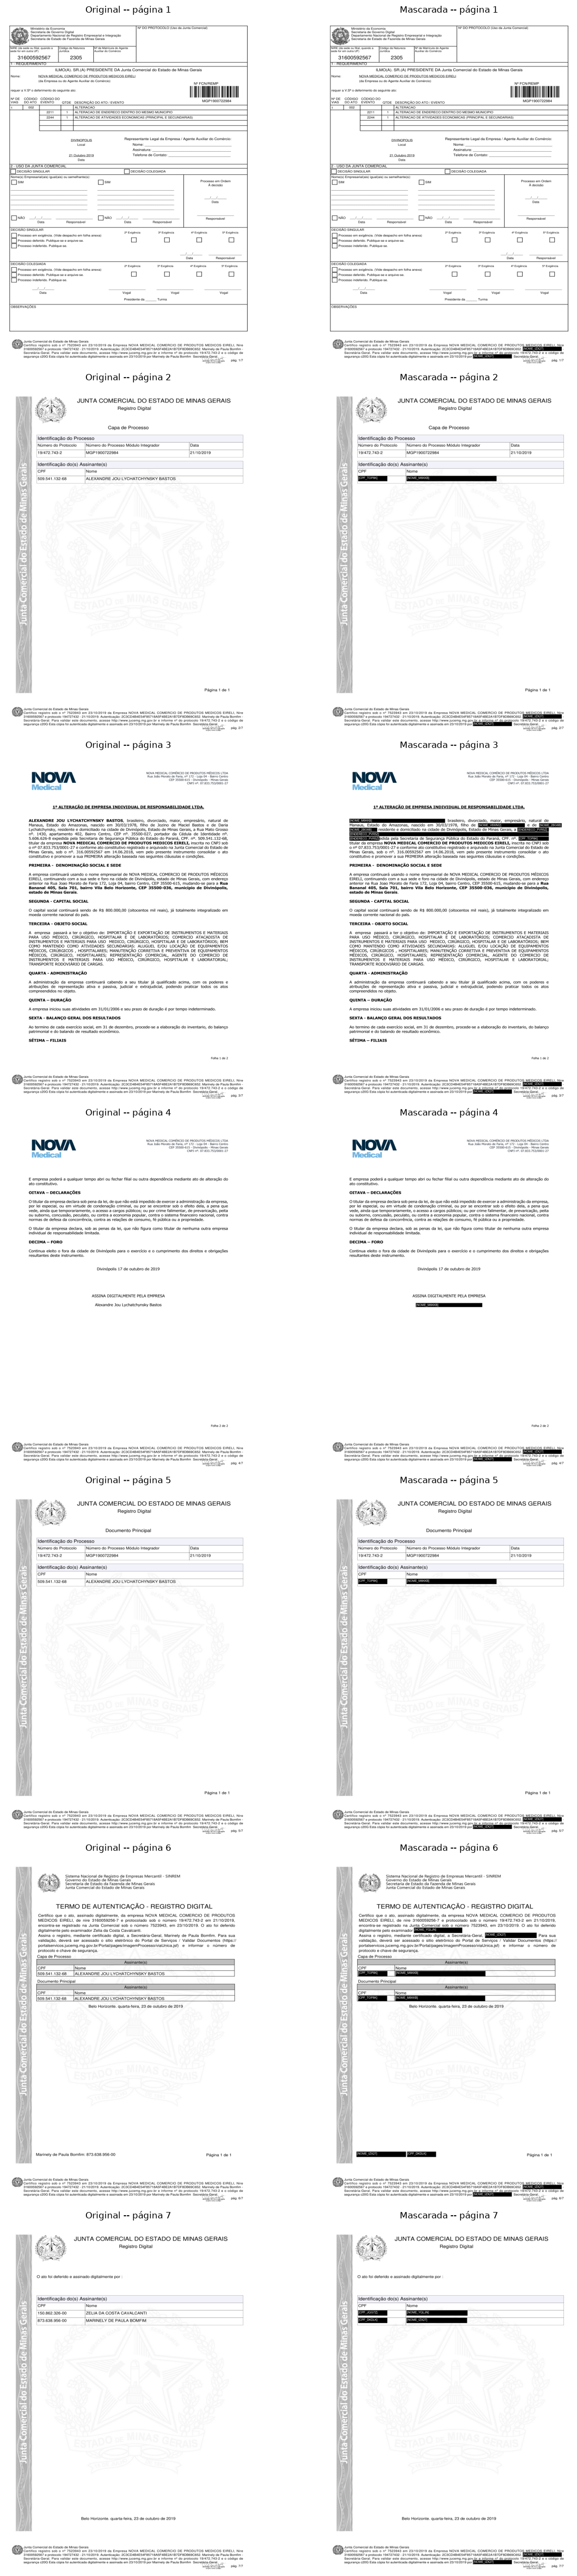

(lendo de _resultados_holdout_3modelos.json)
PERGUNTA: Quem são os sócios da empresa?
----------------------------------------------------------------------------------------------------

--- gemini-2.5-flash-lite ---
SEM MÁSCARA:


MASCARADA (bruta, com marcadores):


MASCARADA (pós desmascaramento -- o que o usuário final veria):


--- gemini-2.5-flash ---
SEM MÁSCARA:
A empresa "NOVA MEDICAL COMERCIO DE PRODUTOS MEDICOS EIRELI" é uma EIRELI (Empresa Individual de
Responsabilidade Limitada), o que significa que ela possui um único titular.  De acordo com o
documento "1ª ALTERAÇÃO DE EMPRESA INDIVIDUAL DE RESPONSABILIDADE LTDA." (página 3), o **único sócio
(titular)** da empresa é:  *   **ALEXANDRE JOU LYCHATCHYNSKY BASTOS** (CPF: 509.541.132-68)

MASCARADA (bruta, com marcadores):
A empresa NOVA MEDICAL COMÉRCIO DE PRODUTOS MÉDICOS EIRELI é uma Empresa Individual de
Responsabilidade Limitada (EIRELI), o que significa que ela possui um único titular, e não sócios.
O titular da empresa

In [11]:
import textwrap

import matplotlib.pyplot as plt


def listar_documentos() -> None:
    for i, d in enumerate(lista_documentos):
        print(f"[{i:2d}] {d['document_id']}")


def escolher_documento(termo: str = None, indice: int = None) -> dict:
    if indice is not None:
        return lista_documentos[indice]
    if termo:
        termo_lower = termo.lower()
        candidatos = [d for d in lista_documentos if termo_lower in d["document_id"].lower()]
        if not candidatos:
            raise ValueError(f"Nenhum documento contém '{termo}'. Rode listar_documentos() pra ver os IDs.")
        if len(candidatos) > 1:
            print(f"[AVISO] {len(candidatos)} documentos combinam com '{termo}', usando o primeiro:")
            for c in candidatos:
                print("  -", c["document_id"])
        return candidatos[0]
    raise ValueError("Informe `termo` (trecho do nome do arquivo) ou `indice` (veja listar_documentos()).")


# ----------------------------------------------------------------------------------
# ESCOLHA AQUI o documento a revisar -- passe o nome do arquivo (exato ou parcial):
DOCUMENTO_ESCOLHIDO = escolher_documento(termo="cm2t2y1fg00b12yqde39j7bwb-Alteração Consolidada 102019.pdf")
# DOCUMENTO_ESCOLHIDO = escolher_documento(indice=4)
# listar_documentos()
# ----------------------------------------------------------------------------------

document_id = DOCUMENTO_ESCOLHIDO["document_id"]
print(f"Documento: {document_id}\n")

extracao = json.loads(DOCUMENTO_ESCOLHIDO["caminho_extracao"].read_text(encoding="utf-8"))
entidades_documento = detectar_entidades_documento(extracao)
catalogo = construir_catalogo(entidades_documento)
print(f"{len(entidades_documento)} entidade(s) detectada(s) -> {len(catalogo)} marcador(es) distintos.\n")

with tempfile.TemporaryDirectory() as pasta_tmp:
    pasta_tmp = Path(pasta_tmp)
    pasta_original = pasta_tmp / "original"
    pasta_mascarado = pasta_tmp / "mascarado"
    pasta_original.mkdir()
    pasta_mascarado.mkdir()

    caminhos_originais = renderizar_paginas(DOCUMENTO_ESCOLHIDO["caminho_pdf"], pasta_original)
    caminhos_mascarados = construir_imagens_mascaradas(DOCUMENTO_ESCOLHIDO["caminho_pdf"], catalogo, pasta_mascarado)

    n_paginas = len(caminhos_originais)
    fig, eixos = plt.subplots(n_paginas, 2, figsize=(14, 7 * n_paginas), squeeze=False)
    for i in range(n_paginas):
        img_original = Image.open(caminhos_originais[i])
        img_mascarada = Image.open(caminhos_mascarados[i])
        eixos[i][0].imshow(img_original)
        eixos[i][0].set_title(f"Original -- página {i + 1}")
        eixos[i][0].axis("off")
        eixos[i][1].imshow(img_mascarada)
        eixos[i][1].set_title(f"Mascarada -- página {i + 1}")
        eixos[i][1].axis("off")
    plt.tight_layout()
    plt.show()

# ----------------------------------------------------------------------------------
# Todas as perguntas e respostas já registradas pra este documento (sem chamar a API de novo)
# ----------------------------------------------------------------------------------
LARGURA = 100
_MODELOS_REVISAO = [("flash_lite", "gemini-2.5-flash-lite"), ("flash", "gemini-2.5-flash"), ("pro", "gemini-2.5-pro")]

resultados_para_revisar = None
for nome_cache in ("_resultados_holdout_3modelos.json", "_resultados_holdout.json"):
    caminho = Path.cwd() / nome_cache
    if caminho.exists():
        resultados_para_revisar = json.loads(caminho.read_text(encoding="utf-8"))
        print(f"(lendo de {nome_cache})")
        break

respostas_doc = (resultados_para_revisar or {}).get(document_id, [])
if not respostas_doc:
    print("Nenhuma resposta registrada pra este documento em cache (rode o Estágio 5 primeiro).")
else:
    for r in respostas_doc:
        print("=" * LARGURA)
        print("PERGUNTA:", r.get("pergunta"))
        print("-" * LARGURA)
        if "erro" in r:
            print("[ERRO]", r["erro"])
            continue
        if "resposta_original" in r:
            # cache antigo (1 modelo só, _resultados_holdout.json)
            print("SEM MÁSCARA:\n" + textwrap.fill(r.get("resposta_original", ""), LARGURA))
            print("\nMASCARADA (bruta, com marcadores):\n" + textwrap.fill(r.get("resposta_mascarada_bruta", ""), LARGURA))
            print("\nMASCARADA (desmascarada -- o que o usuário final veria):\n" + textwrap.fill(r.get("resposta_mascarada_desmascarada", ""), LARGURA))
        else:
            # cache novo (3 modelos, _resultados_holdout_3modelos.json)
            for sufixo, nome_modelo in _MODELOS_REVISAO:
                print(f"\n--- {nome_modelo} ---")
                print("SEM MÁSCARA:\n" + textwrap.fill(r.get(f"resposta_desmascarada_{sufixo}", ""), LARGURA))
                print("\nMASCARADA (bruta, com marcadores):\n" + textwrap.fill(r.get(f"resposta_mascarada_{sufixo}", ""), LARGURA))
                print("\nMASCARADA (pós desmascaramento -- o que o usuário final veria):\n" + textwrap.fill(r.get(f"resposta_pos_desmascaramento_{sufixo}", ""), LARGURA))
        print()

## Estágio 8 -- imprimir resultados por documento/pergunta, por modelo e por estágio (sem GPU)

Lê direto do cache em disco (`_resultados_holdout_3modelos.json`) -- não precisa do modelo
carregado nem de GPU, roda mesmo sem ter executado os Estágios 2-5 nesta sessão do kernel (só
precisa de `json`/`Path`/`textwrap`, já importados antes). Pra cada (documento, pergunta) que
passar nos filtros, imprime os 3 modelos (`flash-lite`/`flash`/`pro`) com os 3 estágios de cada
um: **desmascarada** (documento sem máscara nenhuma), **mascarada** (resposta bruta, com
marcadores) e **pós desmascaramento** (resposta final, depois de substituir os marcadores pelos
valores reais) -- e avisa se sobrou algum marcador vazado (`vazamento_marcador_<modelo>`, ver
`detectar_marcadores_vazados`).

In [12]:
import json as _json
import textwrap as _textwrap
from pathlib import Path as _Path

# Filtra pelos sufixos de MODELOS_TESTE atuais -- mesma correção do Estágio 6 (2026-09-21):
# sem isso, imprimia flash-lite/pro mesmo com MODELOS_TESTE = ["gemini-2.5-flash"], porque o
# cache em disco acumula qualquer modelo já rodado alguma vez.
_MODELOS_IMPRESSAO = [(_SUFIXO_POR_MODELO[m], m) for m in MODELOS_TESTE]


def listar_documentos_cache(arquivo_cache: str = "_resultados_holdout_3modelos.json") -> None:
    caminho = _Path.cwd() / arquivo_cache
    if not caminho.exists():
        print(f"Arquivo {arquivo_cache} não encontrado em {_Path.cwd()}.")
        return
    dados = _json.loads(caminho.read_text(encoding="utf-8"))
    for i, document_id in enumerate(dados):
        print(f"[{i:2d}] {document_id}")


def imprimir_resultados_holdout(
    termo_doc: str = None,
    termo_pergunta: str = None,
    arquivo_cache: str = "_resultados_holdout_3modelos.json",
    largura: int = 100,
) -> None:
    """Imprime, direto do cache em disco, os resultados salvos por documento e pergunta,
    organizados por modelo e por estágio (desmascarada/mascarada/pós desmascaramento).

    `termo_doc`: filtra documentos cujo document_id contém esse texto (case-insensitive).
    `termo_pergunta`: filtra perguntas que contêm esse texto (case-insensitive).
    Sem nenhum filtro, imprime TUDO -- pode ser bastante texto pros 28+ documentos completos.
    """
    caminho = _Path.cwd() / arquivo_cache
    if not caminho.exists():
        print(f"Arquivo {arquivo_cache} não encontrado em {_Path.cwd()}. Rode o Estágio 5 primeiro.")
        return
    dados = _json.loads(caminho.read_text(encoding="utf-8"))

    total_impresso = 0
    for document_id, respostas in dados.items():
        if termo_doc and termo_doc.lower() not in document_id.lower():
            continue
        for r in respostas:
            pergunta = r.get("pergunta", "")
            if termo_pergunta and termo_pergunta.lower() not in pergunta.lower():
                continue

            total_impresso += 1
            print("#" * largura)
            print(f"DOCUMENTO: {document_id}")
            print(f"PERGUNTA:  {pergunta}")
            print("#" * largura)

            if "erro" in r:
                print("[ERRO]", r["erro"], "\n")
                continue

            for sufixo, nome_modelo in _MODELOS_IMPRESSAO:
                if f"resposta_desmascarada_{sufixo}" not in r:
                    continue
                print(f"\n=== {nome_modelo} ===")
                print("-- SEM MÁSCARA (desmascarada) --")
                print(_textwrap.fill(r.get(f"resposta_desmascarada_{sufixo}", "(sem dado)"), largura))
                print("\n-- MASCARADA (bruta, com marcadores) --")
                print(_textwrap.fill(r.get(f"resposta_mascarada_{sufixo}", "(sem dado)"), largura))
                print("\n-- PÓS DESMASCARAMENTO (resposta final) --")
                print(_textwrap.fill(r.get(f"resposta_pos_desmascaramento_{sufixo}", "(sem dado)"), largura))
                vazamento = r.get(f"vazamento_marcador_{sufixo}", "")
                if vazamento:
                    print(f"\n  [AVISO] marcador(es) vazado(s): {vazamento}")
            print()

    if total_impresso == 0:
        print("Nenhum resultado bateu com os filtros (confira termo_doc/termo_pergunta ou rode listar_documentos_cache()).")


# ----------------------------------------------------------------------------------
# Exemplos de uso -- descomente o que quiser:
# ----------------------------------------------------------------------------------
# listar_documentos_cache()
# imprimir_resultados_holdout()  # tudo
imprimir_resultados_holdout(termo_doc="MINAS CAL")  # só um documento, todas as perguntas
# imprimir_resultados_holdout(termo_doc="MINAS CAL", termo_pergunta="junta")  # 1 documento, 1 pergunta
# imprimir_resultados_holdout(termo_pergunta="Gabriel")  # 1 pergunta, todos os documentos


####################################################################################################
DOCUMENTO: cm1iasv3k0031dhqdfn4663iw-Alteração 11 - MINAS CAL.pdf
PERGUNTA:  Quem são os sócios da empresa?
####################################################################################################

=== gemini-2.5-flash ===
-- SEM MÁSCARA (desmascarada) --
Os sócios da empresa MINAS CAL LOGISTICA LTDA são:  *   **Elizabeth Aparecida Soares** (CPF:
721.516.416-00) - com 40% do capital social. *   **Sérgio Lúcio Soares** (CPF: 274.228.956-91) - com
60% do capital social.  Essa informação pode ser encontrada na página 3/10 e confirmada na página
5/10 dos documentos fornecidos, na seção "11ª ALTERAÇÃO E CONSOLIDAÇÃO DE CONTRATO SOCIAL".

-- MASCARADA (bruta, com marcadores) --
Os sócios da empresa são: * [NOME_2DUYT] * [NOME_20BE7]

-- PÓS DESMASCARAMENTO (resposta final) --
Os sócios da empresa são: * ELIZABETH APARECIDA SOARES, * SERGIO LUCIO SOARES

=== gemini-2.5-pro ===
-- S

## Estágio 9 -- imprimir só o que foi avaliado como ERRADO

Usa a avaliação manual salva em `_avaliacao_manual_llm.json` (avaliação feita nesta conversa,
comparando cada resposta com o conteúdo real do documento) pra filtrar e imprimir só as
combinações (documento, pergunta, modelo) marcadas como erro -- seja no **baseline** (o modelo já
erra sem máscara nenhuma) e/ou no **pipeline** (o mascaramento faz o modelo errar). Cada erro vem
com uma nota curta explicando o que especificamente está errado.

In [13]:
def imprimir_apenas_erros(
    incluir_baseline: bool = True,
    incluir_pipeline: bool = True,
    termo_doc: str = None,
    termo_pergunta: str = None,
    arquivo_avaliacao: str = "_avaliacao_manual_llm.json",
    arquivo_cache: str = "_resultados_holdout_3modelos.json",
    largura: int = 100,
) -> None:
    """Imprime só as combinações (documento, pergunta, modelo) marcadas como ERRO na avaliação
    manual -- por padrão qualquer erro (baseline OU pipeline); passe incluir_baseline=False ou
    incluir_pipeline=False pra restringir a só um tipo. Mostra a nota explicando o erro, seguida
    das 3 respostas (desmascarada/mascarada/pós desmascaramento) do modelo em questão."""
    caminho_avaliacao = Path.cwd() / arquivo_avaliacao
    caminho_cache = Path.cwd() / arquivo_cache
    if not caminho_avaliacao.exists():
        print(f"Arquivo {arquivo_avaliacao} não encontrado em {Path.cwd()}.")
        return
    if not caminho_cache.exists():
        print(f"Arquivo {arquivo_cache} não encontrado em {Path.cwd()}.")
        return

    avaliacao = json.loads(caminho_avaliacao.read_text(encoding="utf-8"))
    cache = json.loads(caminho_cache.read_text(encoding="utf-8"))

    total_impresso = 0
    for document_id, perguntas_avaliadas in avaliacao.items():
        if termo_doc and termo_doc.lower() not in document_id.lower():
            continue
        respostas_doc = {r["pergunta"]: r for r in cache.get(document_id, [])}

        for pergunta, modelos_avaliados in perguntas_avaliadas.items():
            if termo_pergunta and termo_pergunta.lower() not in pergunta.lower():
                continue
            r = respostas_doc.get(pergunta)
            if r is None:
                continue

            sufixos_atuais = {_SUFIXO_POR_MODELO[m] for m in MODELOS_TESTE}
            for sufixo, avaliacao_modelo in modelos_avaliados.items():
                if sufixo not in sufixos_atuais:
                    continue
                eh_erro = (incluir_baseline and avaliacao_modelo["baseline"] == "ERRO") or (
                    incluir_pipeline and avaliacao_modelo["pipeline"] == "ERRO"
                )
                if not eh_erro:
                    continue

                total_impresso += 1
                nome_modelo = {"flash_lite": "gemini-2.5-flash-lite", "flash": "gemini-2.5-flash", "pro": "gemini-2.5-pro"}[sufixo]
                print("#" * largura)
                print(f"DOCUMENTO: {document_id}")
                print(f"PERGUNTA:  {pergunta}")
                print(f"MODELO:    {nome_modelo}  (baseline={avaliacao_modelo['baseline']}, pipeline={avaliacao_modelo['pipeline']})")
                if avaliacao_modelo["nota"]:
                    print(f"NOTA:      {avaliacao_modelo['nota']}")
                print("#" * largura)
                print("-- SEM MÁSCARA (desmascarada) --")
                print(textwrap.fill(r.get(f"resposta_desmascarada_{sufixo}", "(sem dado)"), largura))
                print("\n-- MASCARADA (bruta, com marcadores) --")
                print(textwrap.fill(r.get(f"resposta_mascarada_{sufixo}", "(sem dado)"), largura))
                print("\n-- PÓS DESMASCARAMENTO (resposta final) --")
                print(textwrap.fill(r.get(f"resposta_pos_desmascaramento_{sufixo}", "(sem dado)"), largura))
                print()

    if total_impresso == 0:
        print("Nenhum erro bateu com os filtros.")
    else:
        print(f"({total_impresso} combinação(ões) de documento/pergunta/modelo impressa(s))")


# ----------------------------------------------------------------------------------
# Exemplos de uso -- descomente o que quiser:
# ----------------------------------------------------------------------------------
imprimir_apenas_erros()  # todos os erros (baseline OU pipeline), nos 5 documentos avaliados
# imprimir_apenas_erros(incluir_baseline=False)  # só erros causados pelo mascaramento (pipeline)
# imprimir_apenas_erros(incluir_pipeline=False)  # só erros que o modelo já comete sem máscara
# imprimir_apenas_erros(termo_doc="CORTEC")  # só erros de um documento
# imprimir_apenas_erros(termo_pergunta="junta")  # só erros de uma pergunta


####################################################################################################
DOCUMENTO: cm1iasv3k0031dhqdfn4663iw-Alteração 11 - MINAS CAL.pdf
PERGUNTA:  Quem da junta está envolvido nesse documento?
MODELO:    gemini-2.5-pro  (baseline=OK, pipeline=ERRO)
NOTA:      marcador [NOME_YNDMH] vazado no pós -- 3ª pessoa que não existe, catálogo só tem 2
####################################################################################################
-- SEM MÁSCARA (desmascarada) --
Com base nos documentos fornecidos, as seguintes pessoas da Junta Comercial do Estado de Minas
Gerais (JUCEMG) estão envolvidas no processo:  1.  **Carla Campos Carvalho**:     *   **Função**:
Examinadora.     *   **Onde é mencionada**: Na página 9, no "TERMO DE AUTENTICAÇÃO - REGISTRO
DIGITAL", é afirmado que "o ato foi deferido eletronicamente pelo examinador Carla Campos Carvalho".
2.  **Marinely de Paula Bomfim**:     *   **Função**: Secretária-Geral.     *   **Onde é
mencionada**: É